<h1 align="center">ДЗ 2.2: Оптимизация вычислений в Spark</h1>

# Задание 2: Точно ли все так хорошо?

## Запускаем спарк сессию

In [1]:
from pyspark.sql import SparkSession

In [2]:
spark = (
    SparkSession.builder
    .appName("hw22-data-skew")
    .master("spark://spark-master:7077")
    .config("spark.driver.host", "optimization-jupyter")
    .config("spark.executor.memory", "3g")
    .config("spark.executor.cores", "4")
    .config("spark.cores.max", "4")
    .getOrCreate()
)

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/13 22:39:08 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## Подключаемся к S3 (RustFS)

In [3]:
# Параметры подключения к RustFS
S3_ENDPOINT = "http://rustfs:9000"
S3_ACCESS_KEY = "scd2admin"
S3_SECRET_KEY = "scd2-secret-2026"
S3_BUCKET = "spark-optimization"

# Получаем конфигурацию Hadoop
hadoop_conf = spark.sparkContext._jsc.hadoopConfiguration()

# Настройки S3A
hadoop_conf.set("fs.s3a.endpoint", S3_ENDPOINT)
hadoop_conf.set("fs.s3a.access.key", S3_ACCESS_KEY)
hadoop_conf.set("fs.s3a.secret.key", S3_SECRET_KEY)
hadoop_conf.set(
    "fs.s3a.aws.credentials.provider",
    "org.apache.hadoop.fs.s3a.SimpleAWSCredentialsProvider"
)
hadoop_conf.set("fs.s3a.path.style.access", "true")
hadoop_conf.set("fs.s3a.connection.ssl.enabled", "false")
hadoop_conf.set("fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem")
print("Конфигурация S3A установлена")

Конфигурация S3A установлена


In [4]:
from py4j.java_gateway import java_import

In [5]:
java_import(spark.sparkContext._jvm, "org.apache.hadoop.fs.Path")
path = spark.sparkContext._jvm.Path(f"s3a://{S3_BUCKET}/")
fs = path.getFileSystem(hadoop_conf)

26/11/13 22:39:14 WARN MetricsConfig: Cannot locate configuration: tried hadoop-metrics2-s3a-file-system.properties,hadoop-metrics2.properties


## Загрузим данные в S3

Каталог фильмов:

In [6]:
CATALOGUE_LOCAL_PATH = "/home/jupyter/data/task2/catalogue.json"
CATALOGUE_S3_PATH = f"s3a://{S3_BUCKET}/source/catalogue/catalogue.json"

catalogue_local_path = spark.sparkContext._jvm.Path(f"file:{CATALOGUE_LOCAL_PATH}")
catalogue_target_path = spark.sparkContext._jvm.Path(CATALOGUE_S3_PATH)

if fs.exists(catalogue_target_path):
    print("Каталог уже загружен")
else:
    fs.copyFromLocalFile(False, True, catalogue_local_path, catalogue_target_path)
    print("Каталог загружен")

Каталог уже загружен


Данные о просмотрах:

In [7]:
TRANSACTIONS_LOCAL_PATH = "/home/jupyter/data/task2/skew_transactions.csv"
TRANSACTIONS_S3_PATH = f"s3a://{S3_BUCKET}/source/transactions/skew_transactions.csv"

transactions_local_path = spark.sparkContext._jvm.Path(f"file:{TRANSACTIONS_LOCAL_PATH}")
transactions_target_path = spark.sparkContext._jvm.Path(TRANSACTIONS_S3_PATH)

if fs.exists(transactions_target_path):
    print("Файл с транзакциями уже загружен")
else:
    fs.copyFromLocalFile(False, True, transactions_local_path, transactions_target_path)
    print("Файл с транзакциями загружен")

Файл с транзакциями уже загружен


## Читаем из S3

In [8]:
transactions_df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(TRANSACTIONS_S3_PATH)
)

In [12]:
transactions_df.printSchema()

root
 |-- user_uid: integer (nullable = true)
 |-- element_uid: integer (nullable = true)
 |-- watched_time: integer (nullable = true)



In [13]:
print("Количество событий:", transactions_df.count())

Количество событий: 30070692


In [15]:
transactions_df.show(10, truncate=False)

+--------+-----------+------------+
|user_uid|element_uid|watched_time|
+--------+-----------+------------+
|408794  |2714       |7583        |
|247546  |2714       |4450        |
|43556   |2714       |7569        |
|517299  |2714       |1           |
|143593  |2714       |7284        |
|379966  |2714       |7524        |
|445584  |2714       |7121        |
|244115  |2714       |7360        |
|563168  |2714       |2745        |
|33751   |2714       |6822        |
+--------+-----------+------------+
only showing top 10 rows



In [13]:
catalogue_df = spark.read.json(CATALOGUE_S3_PATH)

Py4JJavaError: An error occurred while calling o51.json.
: java.lang.OutOfMemoryError: Java heap space
	at scala.collection.mutable.HashTable.$init$(HashTable.scala:49)
	at scala.collection.mutable.HashMap.<init>(HashMap.scala:45)
	at scala.collection.mutable.HashMap.<init>(HashMap.scala:60)
	at scala.collection.mutable.Map$.empty(Map.scala:65)
	at org.apache.spark.sql.catalyst.trees.TreeNode.<init>(TreeNode.scala:77)
	at org.apache.spark.sql.catalyst.expressions.Expression.<init>(Expression.scala:88)
	at org.apache.spark.sql.catalyst.expressions.UnaryExpression.<init>(Expression.scala:533)
	at org.apache.spark.sql.catalyst.expressions.Alias.<init>(namedExpressions.scala:150)
	at org.apache.spark.sql.catalyst.expressions.CreateNamedStruct.$anonfun$flatten$1(complexTypeCreator.scala:494)
	at org.apache.spark.sql.catalyst.expressions.CreateNamedStruct$$Lambda$1580/0x0000000840d7a840.apply(Unknown Source)
	at scala.collection.immutable.List.map(List.scala:297)
	at org.apache.spark.sql.cat

Проверим структуру файла:

In [11]:
import os

catalogue_local_path = "/home/jupyter/data/task2/catalogue.json"
print("Размер файла:", round(os.path.getsize(catalogue_local_path) / 1024**2, 2), "MB")
with open(catalogue_local_path, "r") as f:
    print(f.read(2000))

Размер файла: 2.7 MB
{"1983":{"type":"movie","availability":["purchase","rent","subscription"],"duration":140,"feature_1":1657223.3965134691,"feature_2":0.7536096584,"feature_3":39,"feature_4":1.1194091265,"feature_5":0.0,"attributes":[1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25]},"3783":{"type":"movie","availability":["purchase","rent","subscription"],"duration":110,"feature_1":35565207.694893226,"feature_2":0.7662537759,"feature_3":41,"feature_4":1.1386044027,"feature_5":0.6547073468,"attributes":[1,26,27,28,29,7,30,31,32,10,14,15,33,19,20,21,34,35,36,37,25]},"5208":{"type":"movie","availability":["purchase","rent","subscription"],"duration":90,"feature_1":13270676.5243101493,"feature_2":0.7654246597,"feature_3":27,"feature_4":1.1318073548,"feature_5":0.5927161087,"attributes":[1,38,39,40,7,41,42,43,14,15,17,18,19,20,21,44,45,46,25]},"9744":{"type":"movie","availability":["purchase","rent","subscription"],"duration":120,"feature_1":21749917.409822803,"feature_2"

=> каталог представляет собой один большой json объект, в котором идентификаторы фильмов используются в качестве ключей, а не отдельных полей. Spark пытался интерпретировать эти ключи как названия столбцов, что приводило к проблемам при построении схемы

Преобрауем каталог в обычную таблицу, где element_uid будет отдельным столбцом:

In [12]:
import json

In [14]:
with open(CATALOGUE_LOCAL_PATH, "r") as f:
    catalogue_data = json.load(f)

catalogue_normalized_path = "/home/jupyter/data/task2/catalogue_normalized.jsonl"

with open(catalogue_normalized_path, "w") as f:
    for element_uid, attributes in catalogue_data.items():
        record = {
            "element_uid": int(element_uid),
            **attributes
        }
        f.write(json.dumps(record) + "\n")

print("Количество записей:", len(catalogue_data))

Количество записей: 10200


Загрузим в s3 преобразованную таблицу:

In [15]:
CATALOGUE_NORMALIZED_S3_PATH = f"s3a://{S3_BUCKET}/source/catalogue/catalogue_normalized.jsonl"

catalogue_normalized_local = spark.sparkContext._jvm.Path(f"file:{catalogue_normalized_path}")
catalogue_normalized_target = spark.sparkContext._jvm.Path(CATALOGUE_NORMALIZED_S3_PATH)

if fs.exists(catalogue_normalized_target):
    print("Преобразованный каталог уже загружен")
else:
    fs.copyFromLocalFile(
        False, True,
        catalogue_normalized_local,
        catalogue_normalized_target
    )
    print("Преобразованный каталог загружен")

Преобразованный каталог загружен


Читаем в spark:

In [16]:
catalogue_df = spark.read.json(CATALOGUE_NORMALIZED_S3_PATH)

In [18]:
catalogue_df.printSchema()

root
 |-- attributes: array (nullable = true)
 |    |-- element: long (containsNull = true)
 |-- availability: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- duration: long (nullable = true)
 |-- element_uid: long (nullable = true)
 |-- feature_1: double (nullable = true)
 |-- feature_2: double (nullable = true)
 |-- feature_3: long (nullable = true)
 |-- feature_4: double (nullable = true)
 |-- feature_5: double (nullable = true)
 |-- type: string (nullable = true)



In [21]:
catalogue_df.show(5)

+--------------------+--------------------+--------+-----------+--------------------+------------+---------+------------+------------+-----+
|          attributes|        availability|duration|element_uid|           feature_1|   feature_2|feature_3|   feature_4|   feature_5| type|
+--------------------+--------------------+--------+-----------+--------------------+------------+---------+------------+------------+-----+
|[1, 2, 3, 4, 5, 6...|[purchase, rent, ...|     140|       1983|   1657223.396513469|0.7536096584|       39|1.1194091265|         0.0|movie|
|[1, 26, 27, 28, 2...|[purchase, rent, ...|     110|       3783|3.5565207694893226E7|0.7662537759|       41|1.1386044027|0.6547073468|movie|
|[1, 38, 39, 40, 7...|[purchase, rent, ...|      90|       5208| 1.327067652431015E7|0.7654246597|       27|1.1318073548|0.5927161087|movie|
|[1, 47, 48, 49, 5...|[purchase, rent, ...|     120|       9744|2.1749917409822803E7|0.7578744427|       26|1.1335254517|0.6547073468|movie|
|[1, 59, 60, 

In [38]:
print("Количество записей:", catalogue_df.count())

Количество записей: 10200


## Исходный INNER JOIN

Выполним исходный INNER JOIN просмотров с каталогом по element_uid через DataFrame API

Для начала преобразуем element_uid к одному типу, в каталоге он имеет тип integer, а в просмотрах - long, поэтому преобразуем к int

In [24]:
from pyspark.sql import functions as F

In [26]:
catalogue_df = catalogue_df.withColumn(
    "element_uid", F.col("element_uid").cast("integer")
)

Теперь выполняем join:

In [27]:
base_join = transactions_df.join(catalogue_df, "element_uid", "inner")

In [40]:
base_join.show(5)

+-----------+--------+------------+--------------------+--------------------+--------+--------------------+----------+---------+------------+------------+-----+
|element_uid|user_uid|watched_time|          attributes|        availability|duration|           feature_1| feature_2|feature_3|   feature_4|   feature_5| type|
+-----------+--------+------------+--------------------+--------------------+--------+--------------------+----------+---------+------------+------------+-----+
|       2714|  408794|        7583|[4052, 4123, 4124...|[purchase, rent, ...|     130|4.2346730221473105E7|0.74050001|       45|1.1419293948|0.5927161087|movie|
|       2714|  247546|        4450|[4052, 4123, 4124...|[purchase, rent, ...|     130|4.2346730221473105E7|0.74050001|       45|1.1419293948|0.5927161087|movie|
|       2714|   43556|        7569|[4052, 4123, 4124...|[purchase, rent, ...|     130|4.2346730221473105E7|0.74050001|       45|1.1419293948|0.5927161087|movie|
|       2714|  517299|           1

Физический план:

In [39]:
base_join.explain("formatted")

== Physical Plan ==
AdaptiveSparkPlan (9)
+- Project (8)
   +- BroadcastHashJoin Inner BuildRight (7)
      :- Filter (2)
      :  +- Scan csv  (1)
      +- BroadcastExchange (6)
         +- Project (5)
            +- Filter (4)
               +- Scan json  (3)


(1) Scan csv 
Output [3]: [user_uid#17, element_uid#18, watched_time#19]
Batched: false
Location: InMemoryFileIndex [s3a://spark-optimization/source/transactions/skew_transactions.csv]
PushedFilters: [IsNotNull(element_uid)]
ReadSchema: struct<user_uid:int,element_uid:int,watched_time:int>

(2) Filter
Input [3]: [user_uid#17, element_uid#18, watched_time#19]
Condition : isnotnull(element_uid#18)

(3) Scan json 
Output [10]: [attributes#22977, availability#22978, duration#22979L, element_uid#22980L, feature_1#22981, feature_2#22982, feature_3#22983L, feature_4#22984, feature_5#22985, type#22986]
Batched: false
Location: InMemoryFileIndex [s3a://spark-optimization/source/catalogue/catalogue_normalized.jsonl]
ReadSchema: struct<a

Спарк выбрал BroadcastHashJoin

## Анализ распределения данных

Проверим element_uid на NULL в просмотрах:

In [31]:
transactions_df.select(
    F.count("*").alias("total_rows"),
    F.sum(F.col("element_uid").isNull().cast("int")).alias("null_keys")
).show()

+----------+---------+
|total_rows|null_keys|
+----------+---------+
|  30070692|        0|
+----------+---------+



Проверим NULL и уникальность ключа каталога:

In [33]:
catalogue_df.select(
    F.count("*").alias("total_rows"),
    F.sum(F.col("element_uid").isNull().cast("int")).alias("null_keys"),
    F.countDistinct("element_uid").alias("unique_keys")
).show()

+----------+---------+-----------+
|total_rows|null_keys|unique_keys|
+----------+---------+-----------+
|     10200|        0|      10200|
+----------+---------+-----------+



Посчитаем частоты ключей в просмотрах:

In [35]:
key_freqs = transactions_df.groupBy("element_uid").count().orderBy(F.desc("count"))
key_freqs.show()

+-----------+--------+
|element_uid|   count|
+-----------+--------+
|       2714|20496000|
|        747|   61272|
|       2639|   61119|
|       3783|   55228|
|       2245|   52942|
|       6127|   52168|
|      10061|   48993|
|       3916|   48243|
|       8771|   47480|
|       3336|   45646|
|       7079|   43872|
|       3567|   42278|
|       6195|   42192|
|       4141|   41704|
|       1016|   41539|
|       7185|   39595|
|       1004|   38929|
|       9467|   37207|
|         72|   36080|
|       1521|   35168|
+-----------+--------+
only showing top 20 rows



Доля наиболее частых значений (топ 10):

In [36]:
top_keys = key_freqs.limit(10).withColumn("part %", 
                                          100 * F.col("count") / F.lit(transactions_df.count()))

In [37]:
top_keys.show()

+-----------+--------+-------------------+
|element_uid|   count|             part %|
+-----------+--------+-------------------+
|       2714|20496000|  68.15938921525317|
|        747|   61272| 0.2037598602652709|
|       2639|   61119|0.20325105920409148|
|       3783|   55228| 0.1836605556001172|
|       2245|   52942| 0.1760584691566127|
|       6127|   52168|0.17348453437652847|
|      10061|   48993| 0.1629260809827722|
|       3916|   48243| 0.1604319581338534|
|       8771|   47480|0.15789460382221998|
|       3336|   45646|0.15179564208233054|
+-----------+--------+-------------------+



## Проблема

Ключ 2714 встречается 20 496 000 раз и составляет 68% всех просмотров, тогда каак второй по частоте ключ 747 — только 0,204%

Таким образом, распределение ключей крайне неравномерное, видим перекос в распределении данных

## Анализ времени выполения

Запустим выполнение base_join, чтобы посмотреть время выполенения задач spark:

In [44]:
base_join.select(
    F.count("type").alias("joined_rows"),
    F.sum("watched_time").alias("total_watched_time")
).show()

+-----------+------------------+
|joined_rows|total_watched_time|
+-----------+------------------+
|   30070692|      198860979525|
+-----------+------------------+



DAG запроса:

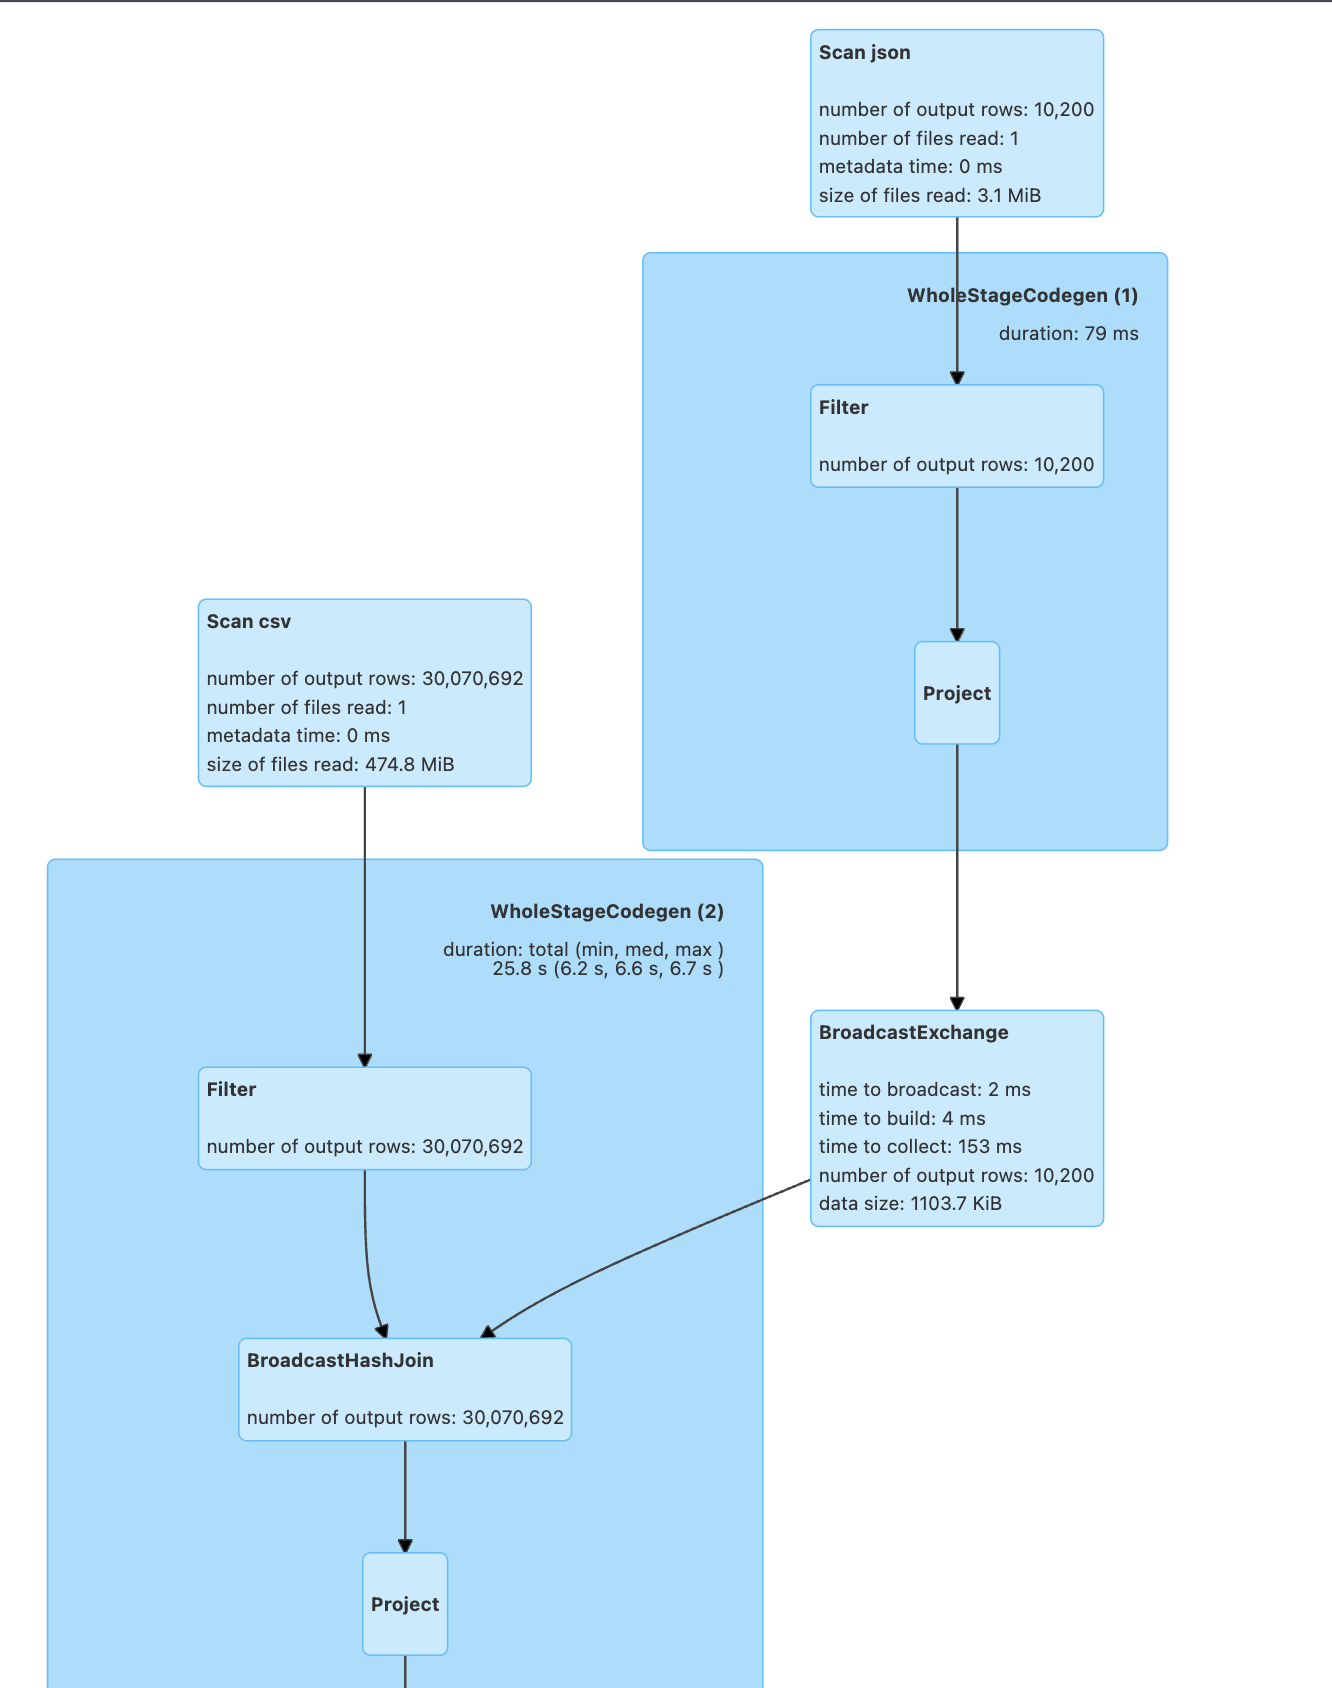

Статистика по времени:

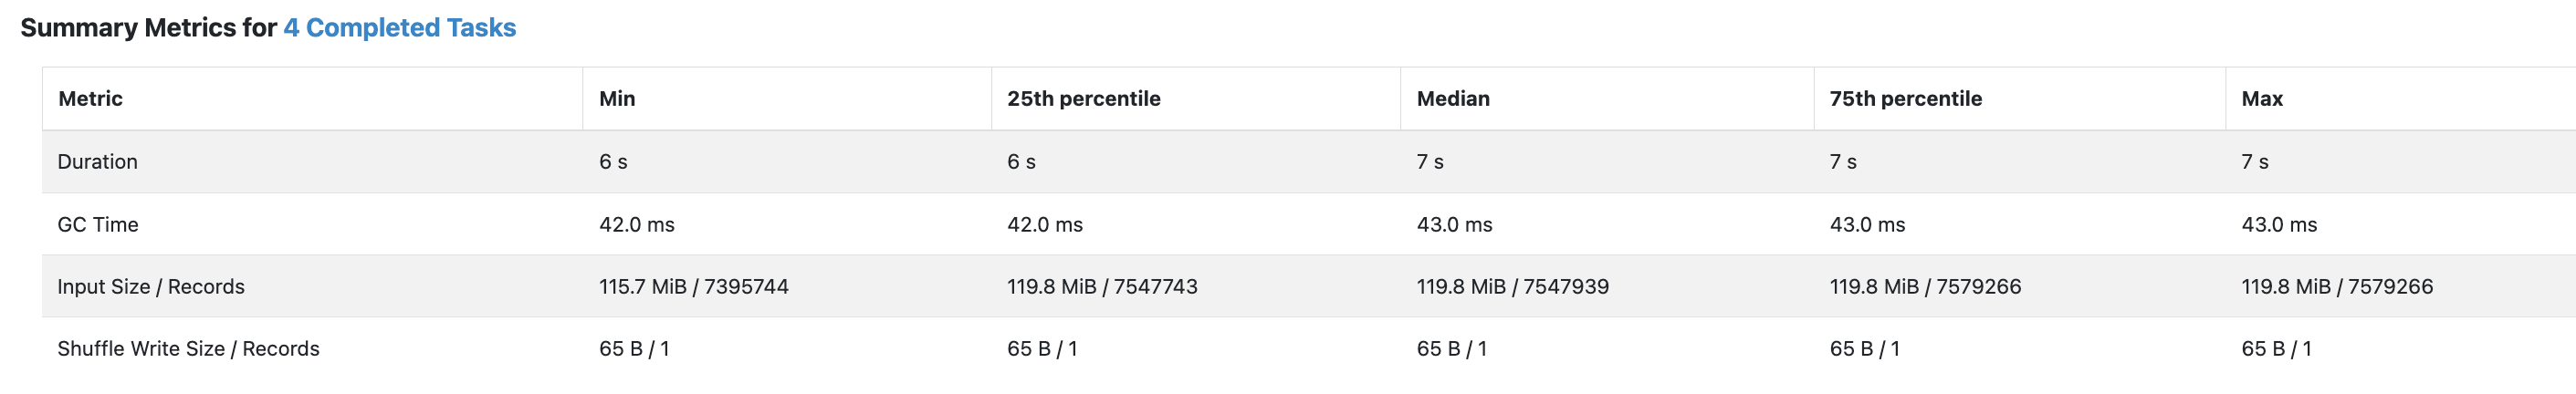

По результатам анализа четырёх задач время выполнения составило 6–7 секунд, а объём обработанных данных 115,7–119,8 MiB на задачу

Таким образом, несмотря на сильный перекос частот ключей в исходных данных, при использовании BroadcastHashJoin выраженного перекоса времени выполнения задач не наблюдается

## Решение проблемы

При анализе выполнения исходного JOIN выяснили, что Spark автоматически выбрал стратегию BroadcastHashJoin, а время выполнения и объём обрабатываемых данных распределены между задачами равномерно. Учитывая небольшой размер каталога фильмов (3,1 MiB), применение данной стратегии является обоснованным. Поэтому в качестве решения проблемы перекоса данных можно явно указывать стратегию соединения broadcast hash join с помощью подсказки hint(BROADCAST)

In [45]:
broadcast_join = transactions_df.join(catalogue_df.hint("BROADCAST"), "element_uid", "inner")

Убедиися, что в физичнском плане BroadcastHashJoin:

In [46]:
broadcast_join.explain("formatted")

== Physical Plan ==
AdaptiveSparkPlan (9)
+- Project (8)
   +- BroadcastHashJoin Inner BuildRight (7)
      :- Filter (2)
      :  +- Scan csv  (1)
      +- BroadcastExchange (6)
         +- Project (5)
            +- Filter (4)
               +- Scan json  (3)


(1) Scan csv 
Output [3]: [user_uid#17, element_uid#18, watched_time#19]
Batched: false
Location: InMemoryFileIndex [s3a://spark-optimization/source/transactions/skew_transactions.csv]
PushedFilters: [IsNotNull(element_uid)]
ReadSchema: struct<user_uid:int,element_uid:int,watched_time:int>

(2) Filter
Input [3]: [user_uid#17, element_uid#18, watched_time#19]
Condition : isnotnull(element_uid#18)

(3) Scan json 
Output [10]: [attributes#22977, availability#22978, duration#22979L, element_uid#22980L, feature_1#22981, feature_2#22982, feature_3#22983L, feature_4#22984, feature_5#22985, type#22986]
Batched: false
Location: InMemoryFileIndex [s3a://spark-optimization/source/catalogue/catalogue_normalized.jsonl]
ReadSchema: struct<a

### Сравнение метрик с исходным вариантом

Запустим выполнение broadcast_join на запросе, аналогичном base_join выше, чтобы посмотреть время выполенения задач spark:

In [47]:
broadcast_join.select(
    F.count("type").alias("joined_rows"),
    F.sum("watched_time").alias("total_watched_time")
).show()

+-----------+------------------+
|joined_rows|total_watched_time|
+-----------+------------------+
|   30070692|      198860979525|
+-----------+------------------+



Посмотрим метрики в ui для 2 варианта:

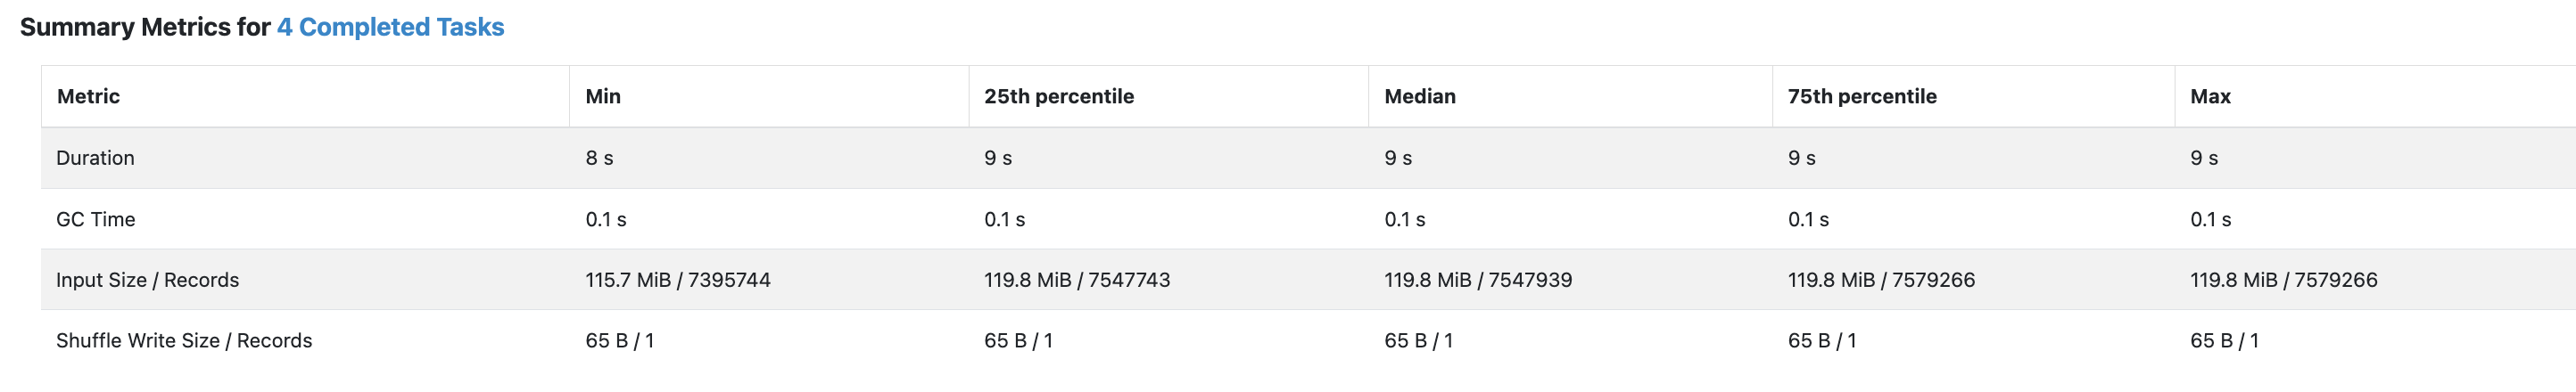

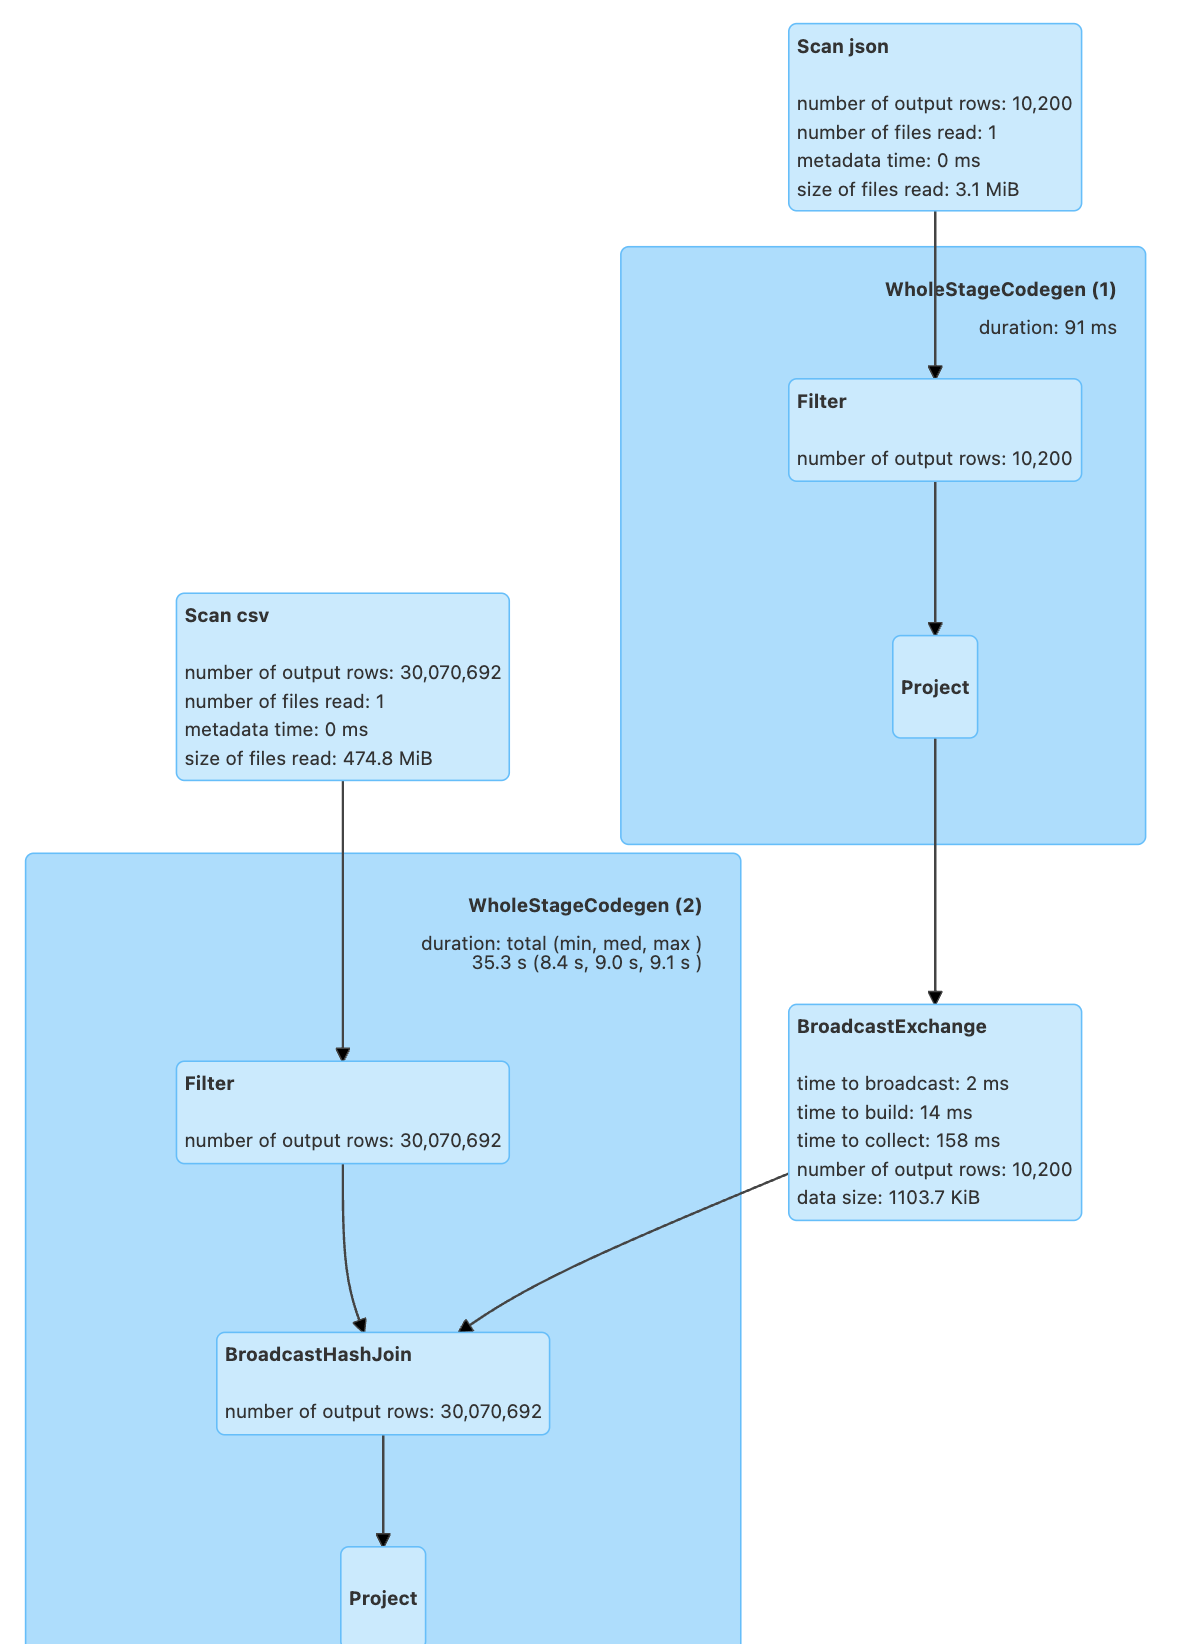

След-но, явное указание broadcast не изменило стратегию соединения: spark и в исходном варианте автоматически выбрал BroadcastHashJoin. Количество выходных строк и распределение входных данных не изменились

При этом время выполнения задач увеличилось: total с 25,8 до 35,3 сек, время отдельных задач с 6-7 на 8-9 сек, медианное время с 6,6 до 9 сек

То есть явное указание стратегии не дало улучшения производительности в данном эксперименте, спарк уже самостоятельно выбрал подходящую стратегию

## Salt join

Для уменьшения перекоса распределения данных добавим соль для самого частотного ключа element_uid = 2714

В соответсвии c [примером](https://github.com/ericxiao251/spark-syntax/blob/master/src/Chapter%207%20-%20High%20Performance%20Code/Section%201.3%20-%20Joins%20on%20Skewed%20Data%20(High%20Frequency%20Keys%20I).ipynb) возьмем 5 значений соли от 0 до 4

Соответствующую запись каталога продублируем для каждого значения соли. Для остальных ключей соль будет равна 0

Сохранность исходных совпадений обеспечивается следующим образом: каждой строке просмотров с горячим ключом присваивается ровно одно значение соли, а соответствующая запись каталога размножается на все возможные значения соли. Поэтому при соединении по паре (element_uid, salt) каждая исходная строка просмотра сопоставляется ровно с одной копией записи каталога. Для остальных ключей соль равна 0 в обеих таблицах, поэтому их совпадения также не изменяются

In [70]:
num_of_partitions = 5
hot_key = 2714

Добавляем случайную соль к записям transactions_df:

In [71]:
salt_value = F.floor(F.rand() * num_of_partitions).cast("int")
transactions_salted = transactions_df.withColumn(
    "salt",
    F.when(
        F.col("element_uid") == hot_key,
        salt_value
    ).otherwise(F.lit(0))
)

Размножаем запись каталога для горячего ключа:

In [72]:
catalogue_hot = catalogue_df.filter(F.col("element_uid") == hot_key).select(
    "*", F.explode(F.array(*[F.lit(i) for i in range(num_of_partitions)])).alias("salt"))

Остальные записи каталога без изменений:

In [73]:
catalogue_other = catalogue_df.filter(F.col("element_uid") != hot_key).withColumn("salt", F.lit(0))

Итоговый кататог:

In [74]:
catalogue_salted = catalogue_hot.unionByName(catalogue_other)

Выполняем salt join, при этом для демонстрации распределения горячего ключа по нескольким партициям принудительно зададим стратегию SortMergeJoin, тк Spark автоматически выбирает BroadcastHashJoin

In [75]:
salted_join = transactions_salted.join(catalogue_salted.hint("MERGE"), ["element_uid", "salt"], "inner").drop("salt")

Фидический план:

In [76]:
salted_join.explain("formatted")

== Physical Plan ==
AdaptiveSparkPlan (18)
+- Project (17)
   +- SortMergeJoin Inner (16)
      :- Sort (5)
      :  +- Exchange (4)
      :     +- Filter (3)
      :        +- Project (2)
      :           +- Scan csv  (1)
      +- Sort (15)
         +- Exchange (14)
            +- Union (13)
               :- Generate (9)
               :  +- Project (8)
               :     +- Filter (7)
               :        +- Scan json  (6)
               +- Project (12)
                  +- Filter (11)
                     +- Scan json  (10)


(1) Scan csv 
Output [3]: [user_uid#17, element_uid#18, watched_time#19]
Batched: false
Location: InMemoryFileIndex [s3a://spark-optimization/source/transactions/skew_transactions.csv]
ReadSchema: struct<user_uid:int,element_uid:int,watched_time:int>

(2) Project
Output [4]: [user_uid#17, element_uid#18, watched_time#19, CASE WHEN (element_uid#18 = 2714) THEN cast(FLOOR((rand(-7877220546830650344) * 5.0)) as int) ELSE 0 END AS salt#23940]
Input [3]: [use

### Сравнение метрик с исходным вариантом

Запустим выполнение salted_join на запросе, аналогичном base_join выше, чтобы посмотреть время выполенения задач spark:

In [77]:
salted_join.select(
    F.count("type").alias("joined_rows"),
    F.sum("watched_time").alias("total_watched_time")
).show()

+-----------+------------------+
|joined_rows|total_watched_time|
+-----------+------------------+
|   30070692|      198860979525|
+-----------+------------------+



Посмотрим метрики в ui:

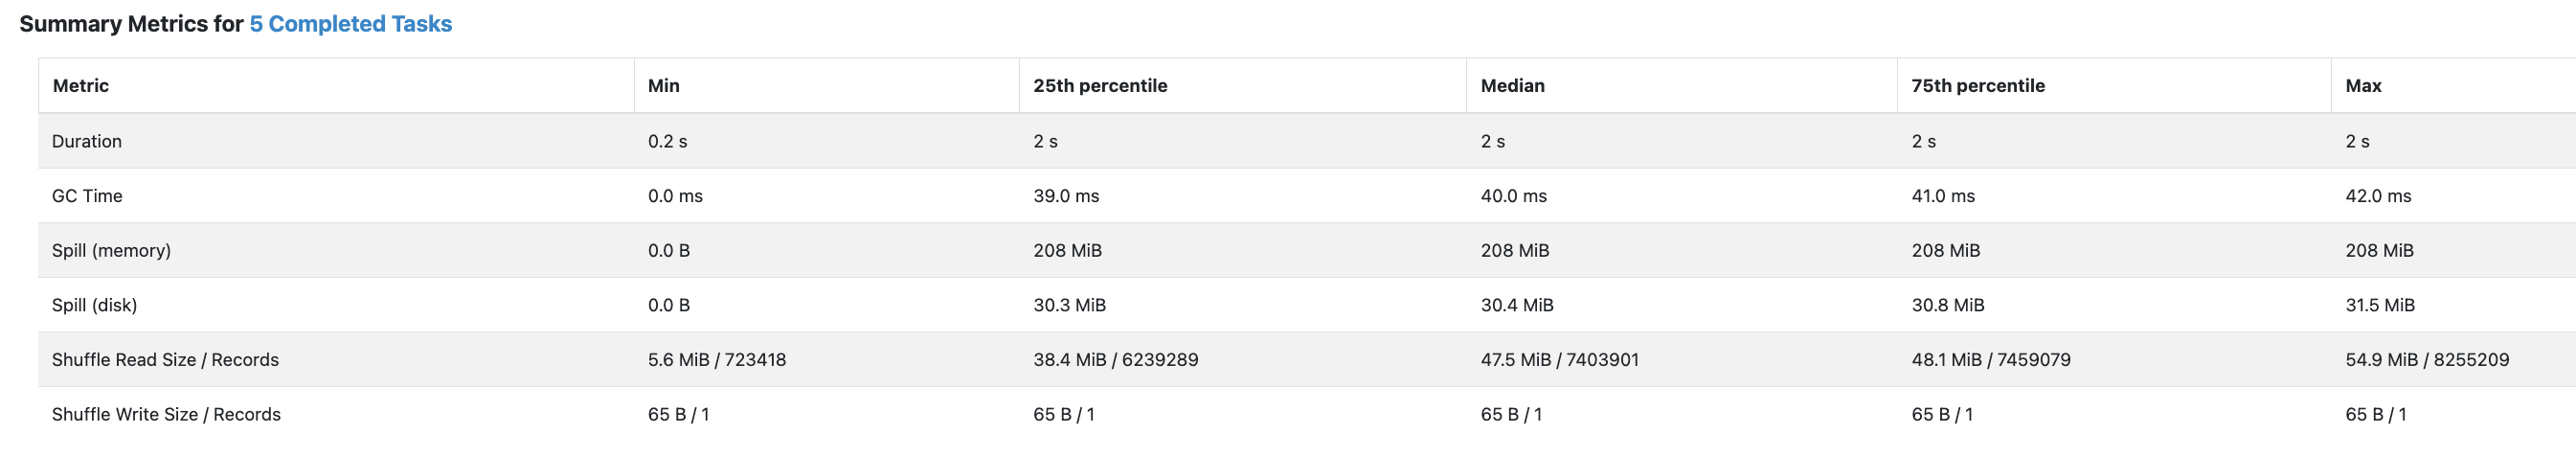

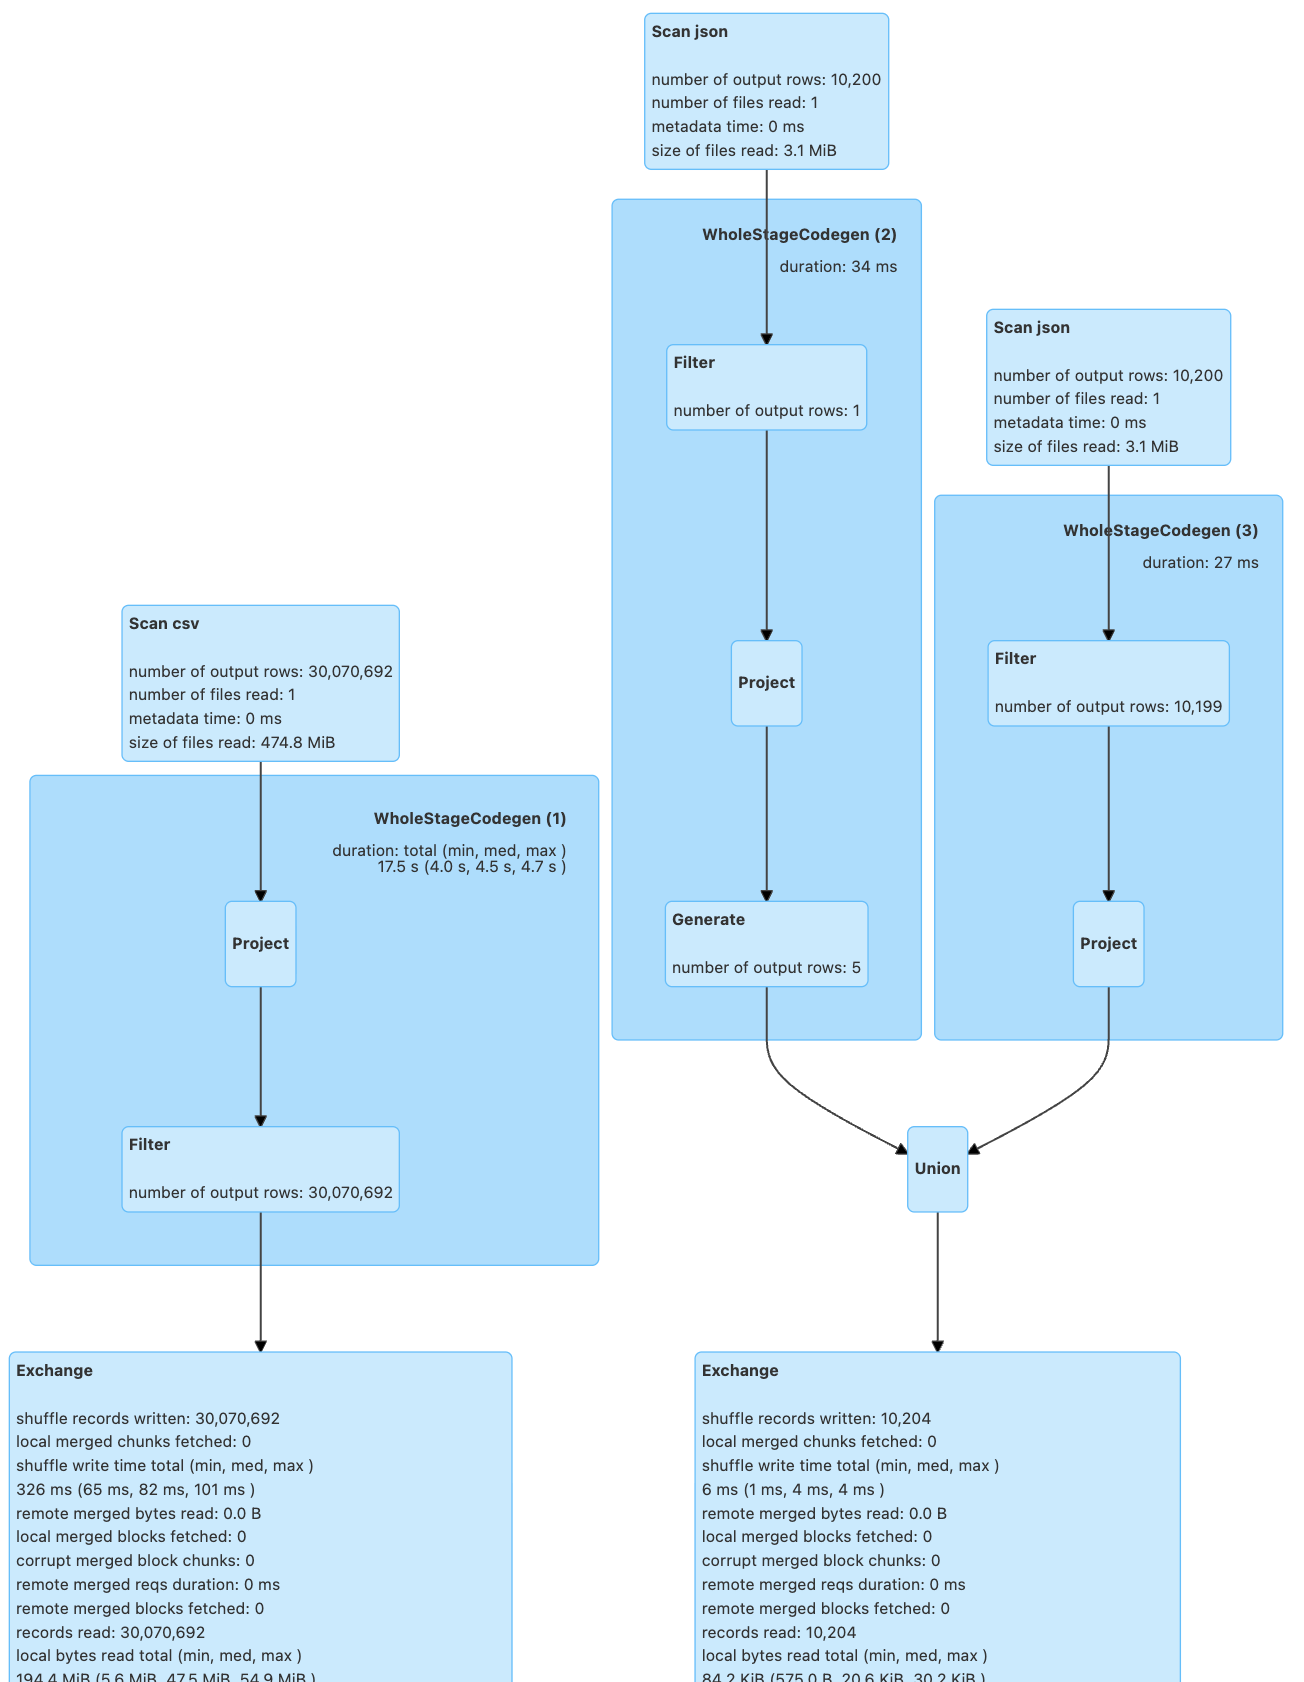
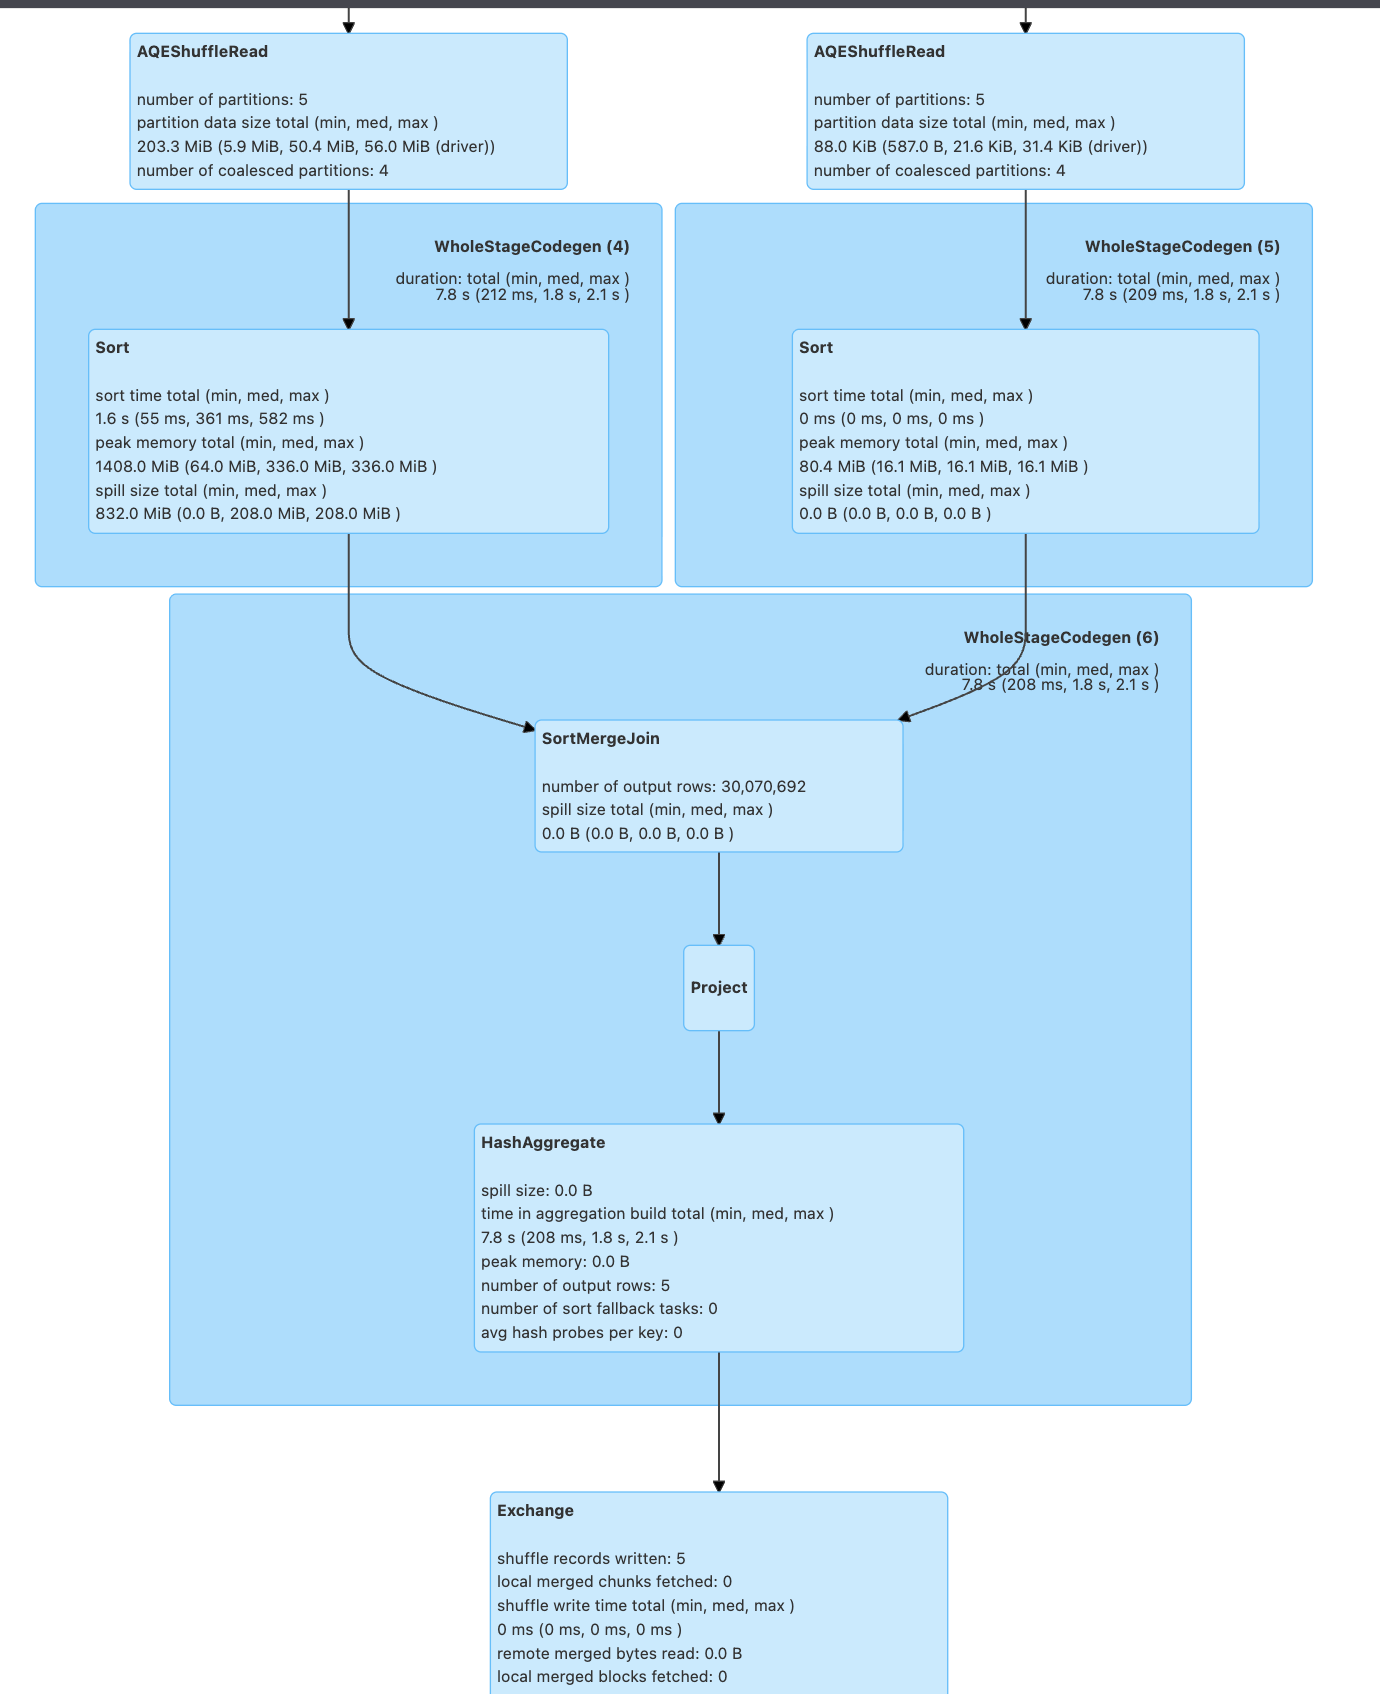

Распределение горячего ключа:

In [80]:
transactions_salted \
    .filter(F.col("element_uid") == hot_key) \
    .groupBy("salt") \
    .count() \
    .orderBy("salt") \
    .show()

+----+-------+
|salt|  count|
+----+-------+
|   0|4098321|
|   1|4096444|
|   2|4099549|
|   3|4100147|
|   4|4101539|
+----+-------+



Использование SortMergeJoin потребовало дополнительных операций shuffle и sort, привело к выгрузке промежуточных данных на диск и не обеспечило ускорения по сравнению с исходным BroadcastHashJoin

Несмотря на практически равномерное распределение горячего ключа между пятью группами, сохранялась неравномерность нагрузки между отдельными задачами по времени выполнения и объёму обрабатываемых данных

=> salt join оказался менее эффективным, тк небольшой размер каталога позволял использовать более экономичный BroadcastHashJoin

## Сравнение результатов

Для проверки эквивалентности результатов сравним исходный join с вариантами Broadcast Join и Salt Join

Для этого используем exceptAll() в обоих направлениях, которая учитывает повторяющиеся строки. Перед сравнением приведём результаты к одинаковому порядку столбцов.

Приводим результаты к одинаковому порядку столбцов:

In [83]:
base_result = base_join.select(*base_join.columns)
broadcast_result = broadcast_join.select(*base_join.columns)
salted_result = salted_join.select(*base_join.columns)

In [84]:
def compare_results(reference, candidate, name):
    missing = reference.exceptAll(candidate).count()
    extra = candidate.exceptAll(reference).count()

    print(f"{name}:")
    print(f"  Строк, отсутствующих в результате: {missing}")
    print(f"  Лишних строк в результате: {extra}")
    print(f"  Полное совпадение: {missing == 0 and extra == 0}")

In [85]:
compare_results(
    base_result,
    broadcast_result,
    "Исходный JOIN и Broadcast JOIN"
)

compare_results(
    base_result,
    salted_result,
    "Исходный JOIN и Salt Join"
)

Исходный JOIN и Broadcast JOIN:
  Строк, отсутствующих в результате: 0
  Лишних строк в результате: 0
  Полное совпадение: True


Исходный JOIN и Salt Join:
  Строк, отсутствующих в результате: 0
  Лишних строк в результате: 0
  Полное совпадение: True


Все результаты совпадают

# Вывод

В качестве итогового решения выбираем исходный INNER JOIN с BroadcastHashJoin, автоматически выбранным spark. Он показал наименьшее время выполнения и не требует дополнительных операций shuffle и sort